# Projeto 2 – Análise de Sentimentos em Avaliações de Produtos (PLN)
## Notebook 04: Avaliação Experimental, Análise de Erros, Ruído de Rótulos e Desempenho por Categoria

**Responsável:** Pessoa 3 (Avaliação Crítica, Ética e Interface Streamlit)  
**Disciplina:** Inteligência Artificial – Unidade 3 (IFPB – Bacharelado em Engenharia da Computação)

---

### Objetivos deste Notebook (alinhados às Seções 2.5.5, 2.6 e 2.8 do edital)
1. **Consolidar e comparar** as 16 configurações da grade padrão e os 4 classificadores ajustados via validação cruzada, destacando o **F1-Score Macro** frente ao desequilíbrio de classes.
2. **Analisar detalhadamente as matrizes de confusão** e a capacidade de detecção de avaliações negativas (**Recall e F1 Negativo**).
3. **Responder com evidências quantitativas e exemplos reais do `X_test`** às **5 perguntas obrigatórias da Seção 2.6**:
   - *Pergunta 1:* Qual configuração apresentou melhor resultado?
   - *Pergunta 2:* O modelo consegue identificar adequadamente avaliações negativas?
   - *Pergunta 3:* Quais erros aparecem com maior frequência (classe Neutra e avaliações mistas)?
   - *Pergunta 4:* A regra de conversão de notas em sentimentos introduz ruído nos rótulos?
   - *Pergunta 5:* O desempenho se mantém em avaliações de produtos ou categorias diferentes?
4. **Comparar com o cenário binário** (descartando a nota 3) sem *data leakage*.
5. **Validar inferência e explicabilidade por token** em avaliações inéditas e exportar `reports/evaluation_summary.json` e figuras `12..15_*.png` em 300 DPI para o Relatório Técnico e o aplicativo Streamlit (`app.py`).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

# Garantir que a raiz do projeto esteja no sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import PERSONAL_DATA_COLUMNS
from src.evaluation import (
    CLF_LABELS,
    EVALUATION_SUMMARY_PATH,
    FIGURES_DIR,
    REP_LABELS,
    analyze_error_breakdown,
    analyze_label_noise,
    build_comparison_dataframe,
    build_test_predictions_df,
    compute_detailed_metrics,
    evaluate_binary_scenario,
    evaluate_by_category,
    extract_error_examples,
    load_best_pipeline,
    load_model_results,
    plot_category_performance,
    plot_confusion_matrices_comparison,
    plot_error_and_noise_analysis,
    plot_negative_recall_comparison,
    predict_single_review,
)
from src.models import get_split

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 20)

model_results = load_model_results()
best_pipe = load_best_pipeline()

# Mesmo split estratificado 80/20 (random_state=42) usado na modelagem pela Pessoa 2
df, X_train, X_test, y_train, y_test = get_split(sample_size=None)
df_pred = build_test_predictions_df(df, X_test, y_test, model_obj=best_pipe)

# Garantia de privacidade (Seção 2.8)
assert all(col not in df_pred.columns for col in PERSONAL_DATA_COLUMNS), "Coluna pessoal detectada!"

print(f"Treino: {len(X_train):,} | Teste: {len(X_test):,}")
print("Colunas no DataFrame de avaliação (sem dados pessoais):", list(df_pred.columns))

Treino: 101,352 | Teste: 25,338
Colunas no DataFrame de avaliação (sem dados pessoais): ['review_text_original', 'review_text_clean', 'overall_rating', 'sentiment_real', 'sentiment_id_real', 'site_category_lv1', 'recommend_to_a_friend', 'word_count', 'char_count', 'sentiment_id_pred', 'sentiment_pred', 'correct', 'prob_Negativo', 'prob_Neutro', 'prob_Positivo', 'confidence', 'is_calibrated_proba']


---
## 1. Pergunta 1 — Qual configuração apresentou melhor resultado?

A tabela a seguir reúne todas as **16 combinações** da grade padrão (BoW e TF-IDF × unigramas e uni+bigramas × Naive Bayes, Regressão Logística padrão, Regressão Logística `balanced` e Linear SVM `balanced`) e os **4 modelos ajustados via `GridSearchCV`** em `X_train` (`tfidf_bi`), ordenados pela métrica principal **F1-Macro**.

In [2]:
df_comp = build_comparison_dataframe(model_results)
cols_show = [
    "rank", "etapa", "representacao_label", "classificador_label", "hiperparametros",
    "cv_f1_macro", "f1_macro", "accuracy", "f1_Negativo", "f1_Neutro", "f1_Positivo",
    "recall_Negativo", "recall_Neutro"
]
display(df_comp[cols_show].round(4))

final_metrics = compute_detailed_metrics(df_pred["sentiment_id_real"], df_pred["sentiment_id_pred"])
best_acc_row = df_comp.loc[df_comp["accuracy"].idxmax()]

print(f"\nModelo Final (selecionado por CV em X_train): {REP_LABELS[model_results['final']['representation']]} + "
      f"{CLF_LABELS[model_results['final']['classifier']]} {model_results['final']['best_params']}")
print(f"  CV F1-Macro:   {model_results['final']['cv_f1_macro']:.4f}")
print(f"  Test F1-Macro: {final_metrics['f1_macro']:.4f} | Acurácia: {final_metrics['accuracy']:.4f} | "
      f"F1-Weighted: {final_metrics['f1_weighted']:.4f}")
print(f"\nContraste com maior Acurácia isolada: {best_acc_row['representacao_label']} + {best_acc_row['classificador_label']} "
      f"-> Acc={best_acc_row['accuracy']:.4f}, mas F1-Macro={best_acc_row['f1_macro']:.4f} e Recall Neutro={best_acc_row['recall_Neutro']:.4f}")

,rank,etapa,representacao_label,classificador_label,hiperparametros,cv_f1_macro,f1_macro,accuracy,f1_Negativo,f1_Neutro,f1_Positivo,recall_Negativo,recall_Neutro
0,1,Ajustado (CV),TF-IDF (Uni+Bigramas),Linear SVM (balanced),C=0.1,0.7248,0.7318,0.8378,0.8671,0.4269,0.9015,0.9138,0.3913
1,2,Grade Padrão,TF-IDF (Uni+Bigramas),Regressão Logística (balanced),padrão,NaN,0.7233,0.7992,0.8634,0.4398,0.8666,0.8917,0.5484
2,3,Ajustado (CV),TF-IDF (Uni+Bigramas),Regressão Logística (balanced),C=1,0.7171,0.7233,0.7992,0.8634,0.4398,0.8666,0.8917,0.5484
3,4,Grade Padrão,TF-IDF (Uni+Bigramas),Linear SVM (balanced),padrão,NaN,0.7100,0.8221,0.8610,0.3779,0.8911,0.8913,0.3588
4,5,Grade Padrão,BoW (Uni+Bigramas),Naive Bayes,padrão,NaN,0.7073,0.8143,0.8404,0.3914,0.8903,0.8666,0.3932
5,6,Grade Padrão,BoW (Uni+Bigramas),Regressão Logística (balanced),padrão,NaN,0.7069,0.8006,0.8534,0.3948,0.8725,0.8727,0.4418
6,7,Ajustado (CV),TF-IDF (Uni+Bigramas),Regressão Logística,C=3,0.7010,0.7006,0.8395,0.8706,0.3294,0.9020,0.9011,0.2490
7,8,Grade Padrão,TF-IDF (Uni+Bigramas),Regressão Logística,padrão,NaN,0.6993,0.8452,0.8729,0.3193,0.9058,0.9072,0.2256
8,9,Grade Padrão,TF-IDF (Unigramas),Regressão Logística (balanced),padrão,NaN,0.6981,0.7681,0.8424,0.4100,0.8419,0.8627,0.5614
9,10,Grade Padrão,BoW (Uni+Bigramas),Regressão Logística,padrão,NaN,0.6978,0.8302,0.8602,0.3359,0.8973,0.8753,0.2745



Modelo Final (selecionado por CV em X_train): TF-IDF (Uni+Bigramas) + Linear SVM (balanced) {'clf__C': 0.1}
  CV F1-Macro:   0.7248
  Test F1-Macro: 0.7318 | Acurácia: 0.8378 | F1-Weighted: 0.8333

Contraste com maior Acurácia isolada: TF-IDF (Uni+Bigramas) + Regressão Logística -> Acc=0.8452, mas F1-Macro=0.6993 e Recall Neutro=0.2256


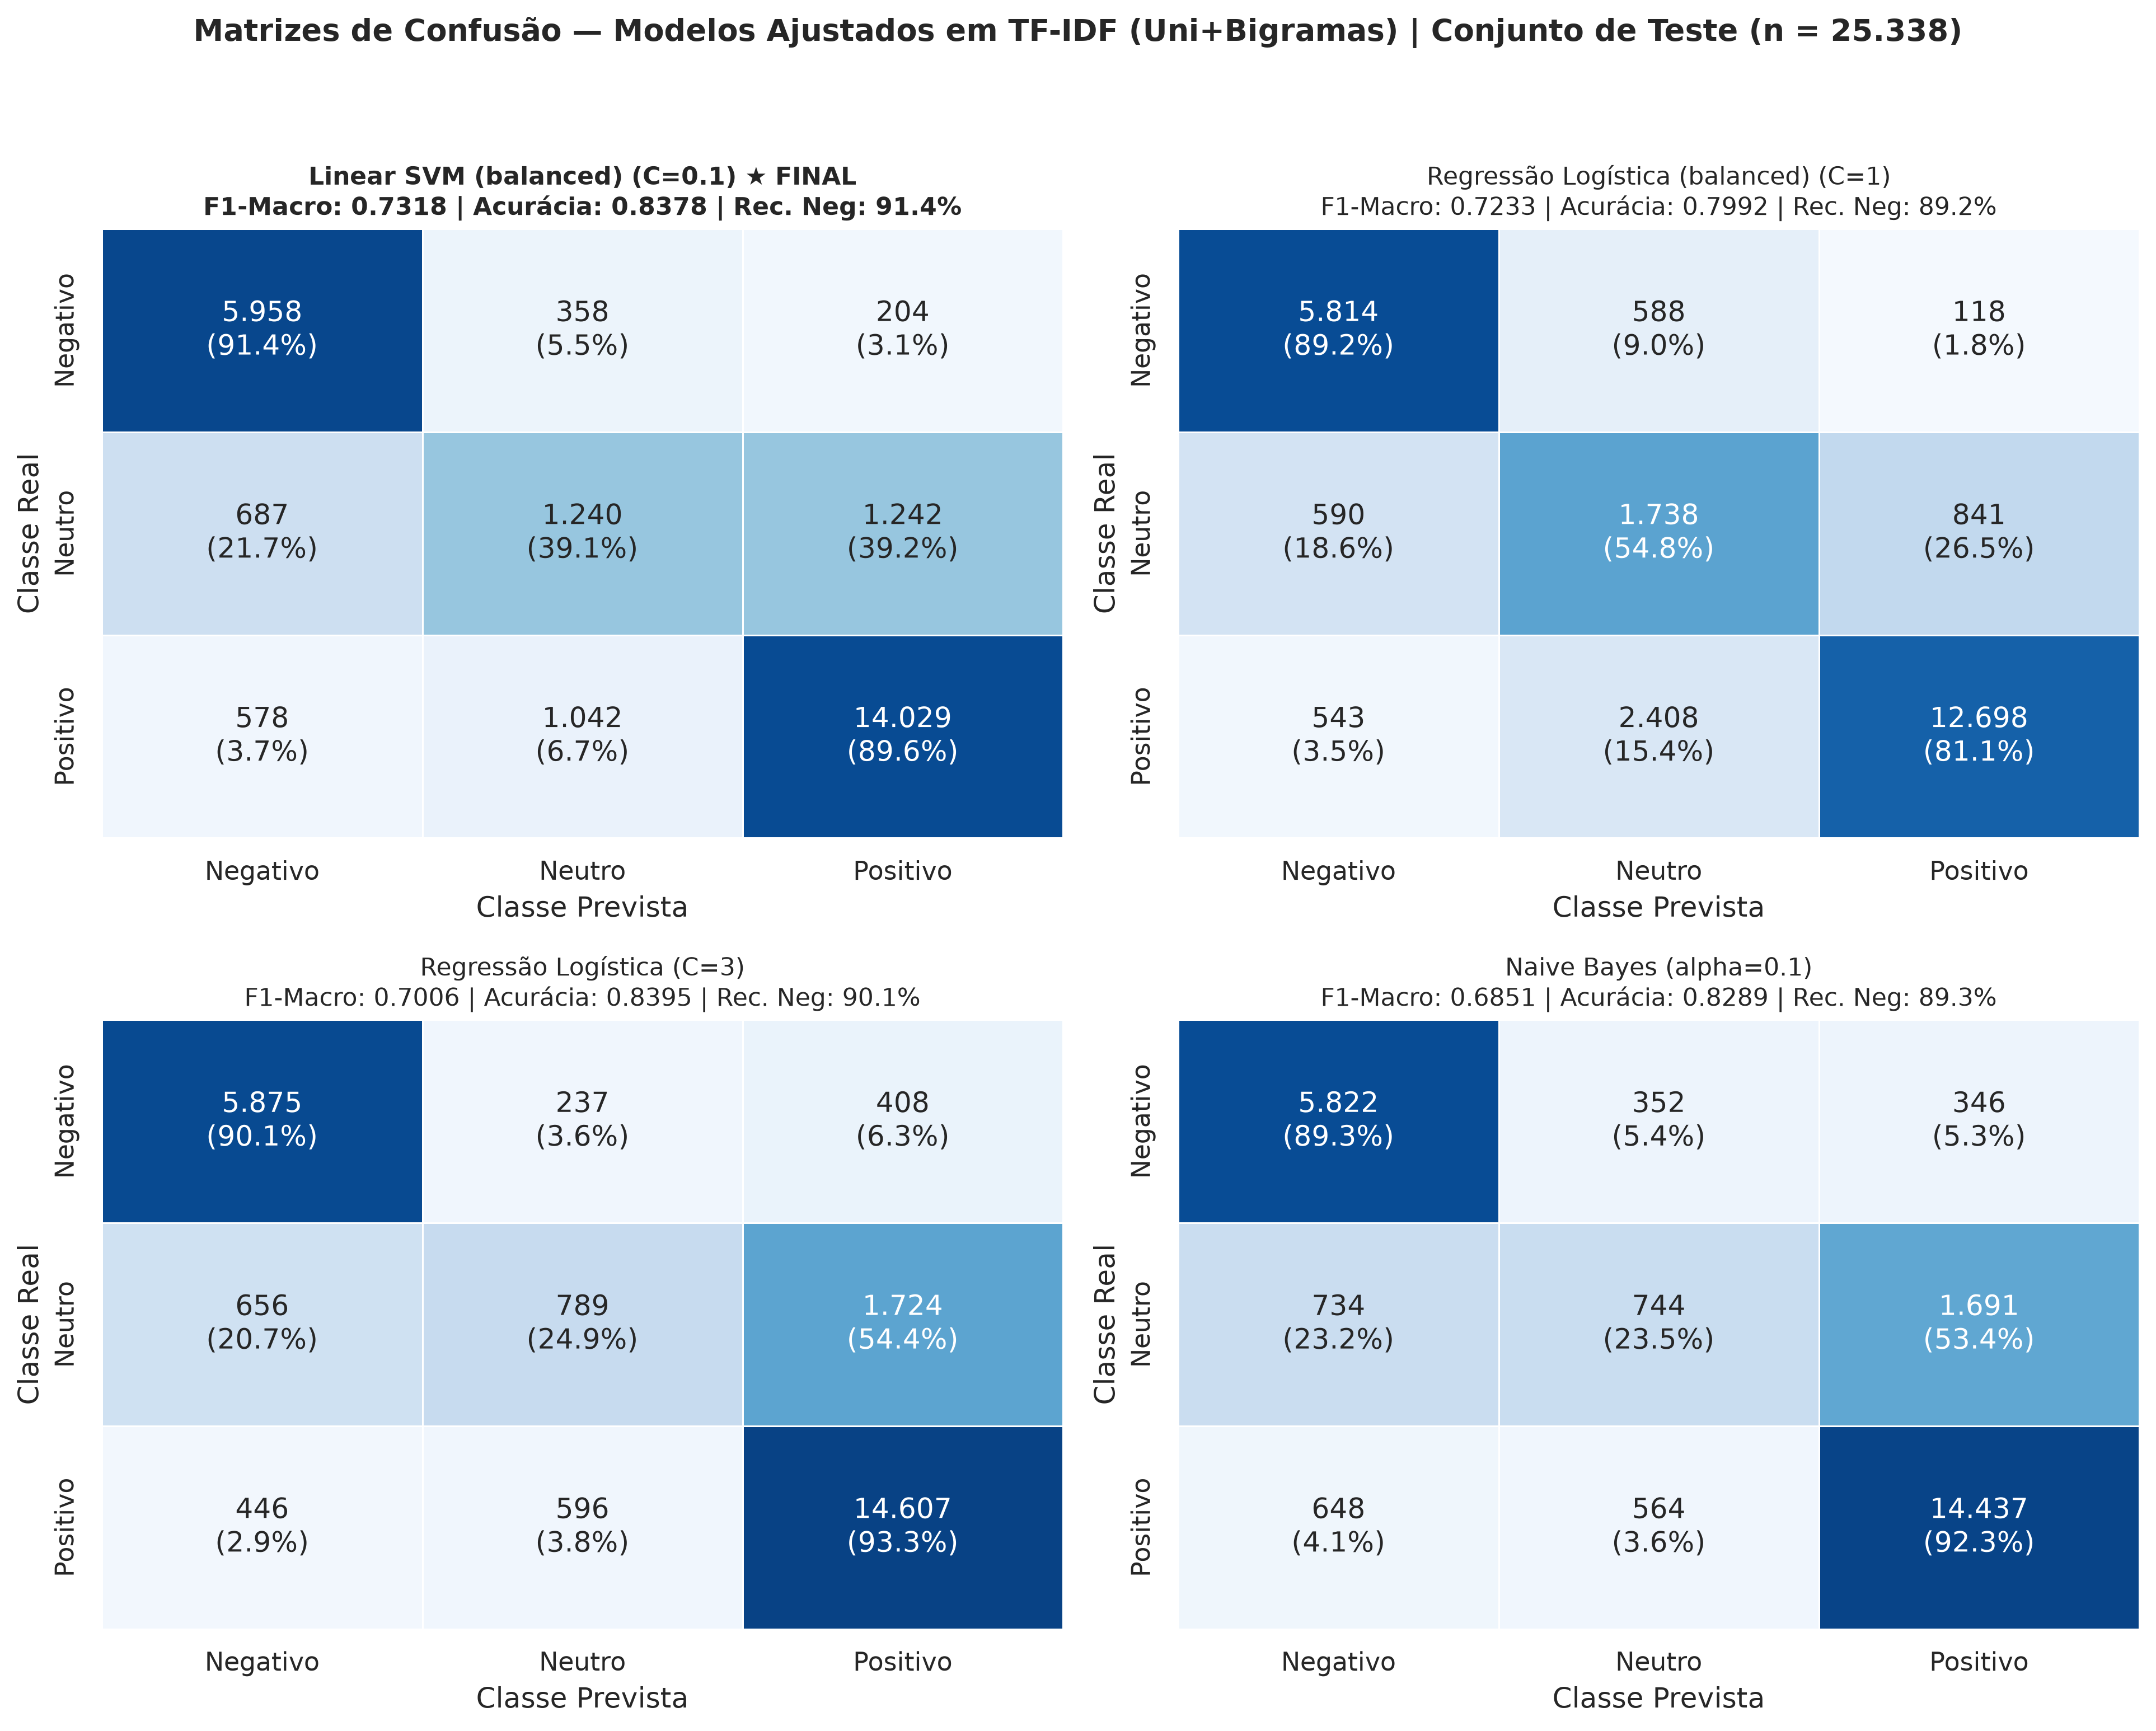

In [3]:
fig12_path = plot_confusion_matrices_comparison(model_results)
display(Image(filename=str(fig12_path)))

---
## 2. Pergunta 2 — O modelo consegue identificar adequadamente avaliações negativas?

Para aplicações reais de atendimento ao cliente e gestão de reputação, perder reclamações reais (baixo *Recall* Negativo) é crítico. Abaixo comparamos **Precisão, Recall e F1 da classe Negativa** em `tfidf_bi`, avaliando também o efeito de `class_weight='balanced'` e do ajuste de `C` no Linear SVM.

,etapa,classificador_label,hiperparametros,precision_Negativo,recall_Negativo,f1_Negativo,recall_Neutro,f1_macro,accuracy
0,Ajustado (CV),Linear SVM (balanced),C=0.1,0.8249,0.9138,0.8671,0.3913,0.7318,0.8378
7,Grade Padrão,Regressão Logística,padrão,0.8410,0.9072,0.8729,0.2256,0.6993,0.8452
6,Ajustado (CV),Regressão Logística,C=3,0.8421,0.9011,0.8706,0.2490,0.7006,0.8395
12,Ajustado (CV),Naive Bayes,alpha=0.1,0.8082,0.8929,0.8484,0.2348,0.6851,0.8289
18,Grade Padrão,Naive Bayes,padrão,0.8119,0.8928,0.8504,0.0243,0.5969,0.8271
1,Grade Padrão,Regressão Logística (balanced),padrão,0.8369,0.8917,0.8634,0.5484,0.7233,0.7992
2,Ajustado (CV),Regressão Logística (balanced),C=1,0.8369,0.8917,0.8634,0.5484,0.7233,0.7992
3,Grade Padrão,Linear SVM (balanced),padrão,0.8326,0.8913,0.8610,0.3588,0.7100,0.8221


No modelo final (n_negativos=6,520):
  Corretamente detectados como Negativo: 5,958 (91.38% — Recall Negativo)
  Suavizados para Neutro:                358 (5.49%)
  Confundidos com Positivo (erro grave): 204 (3.13%)


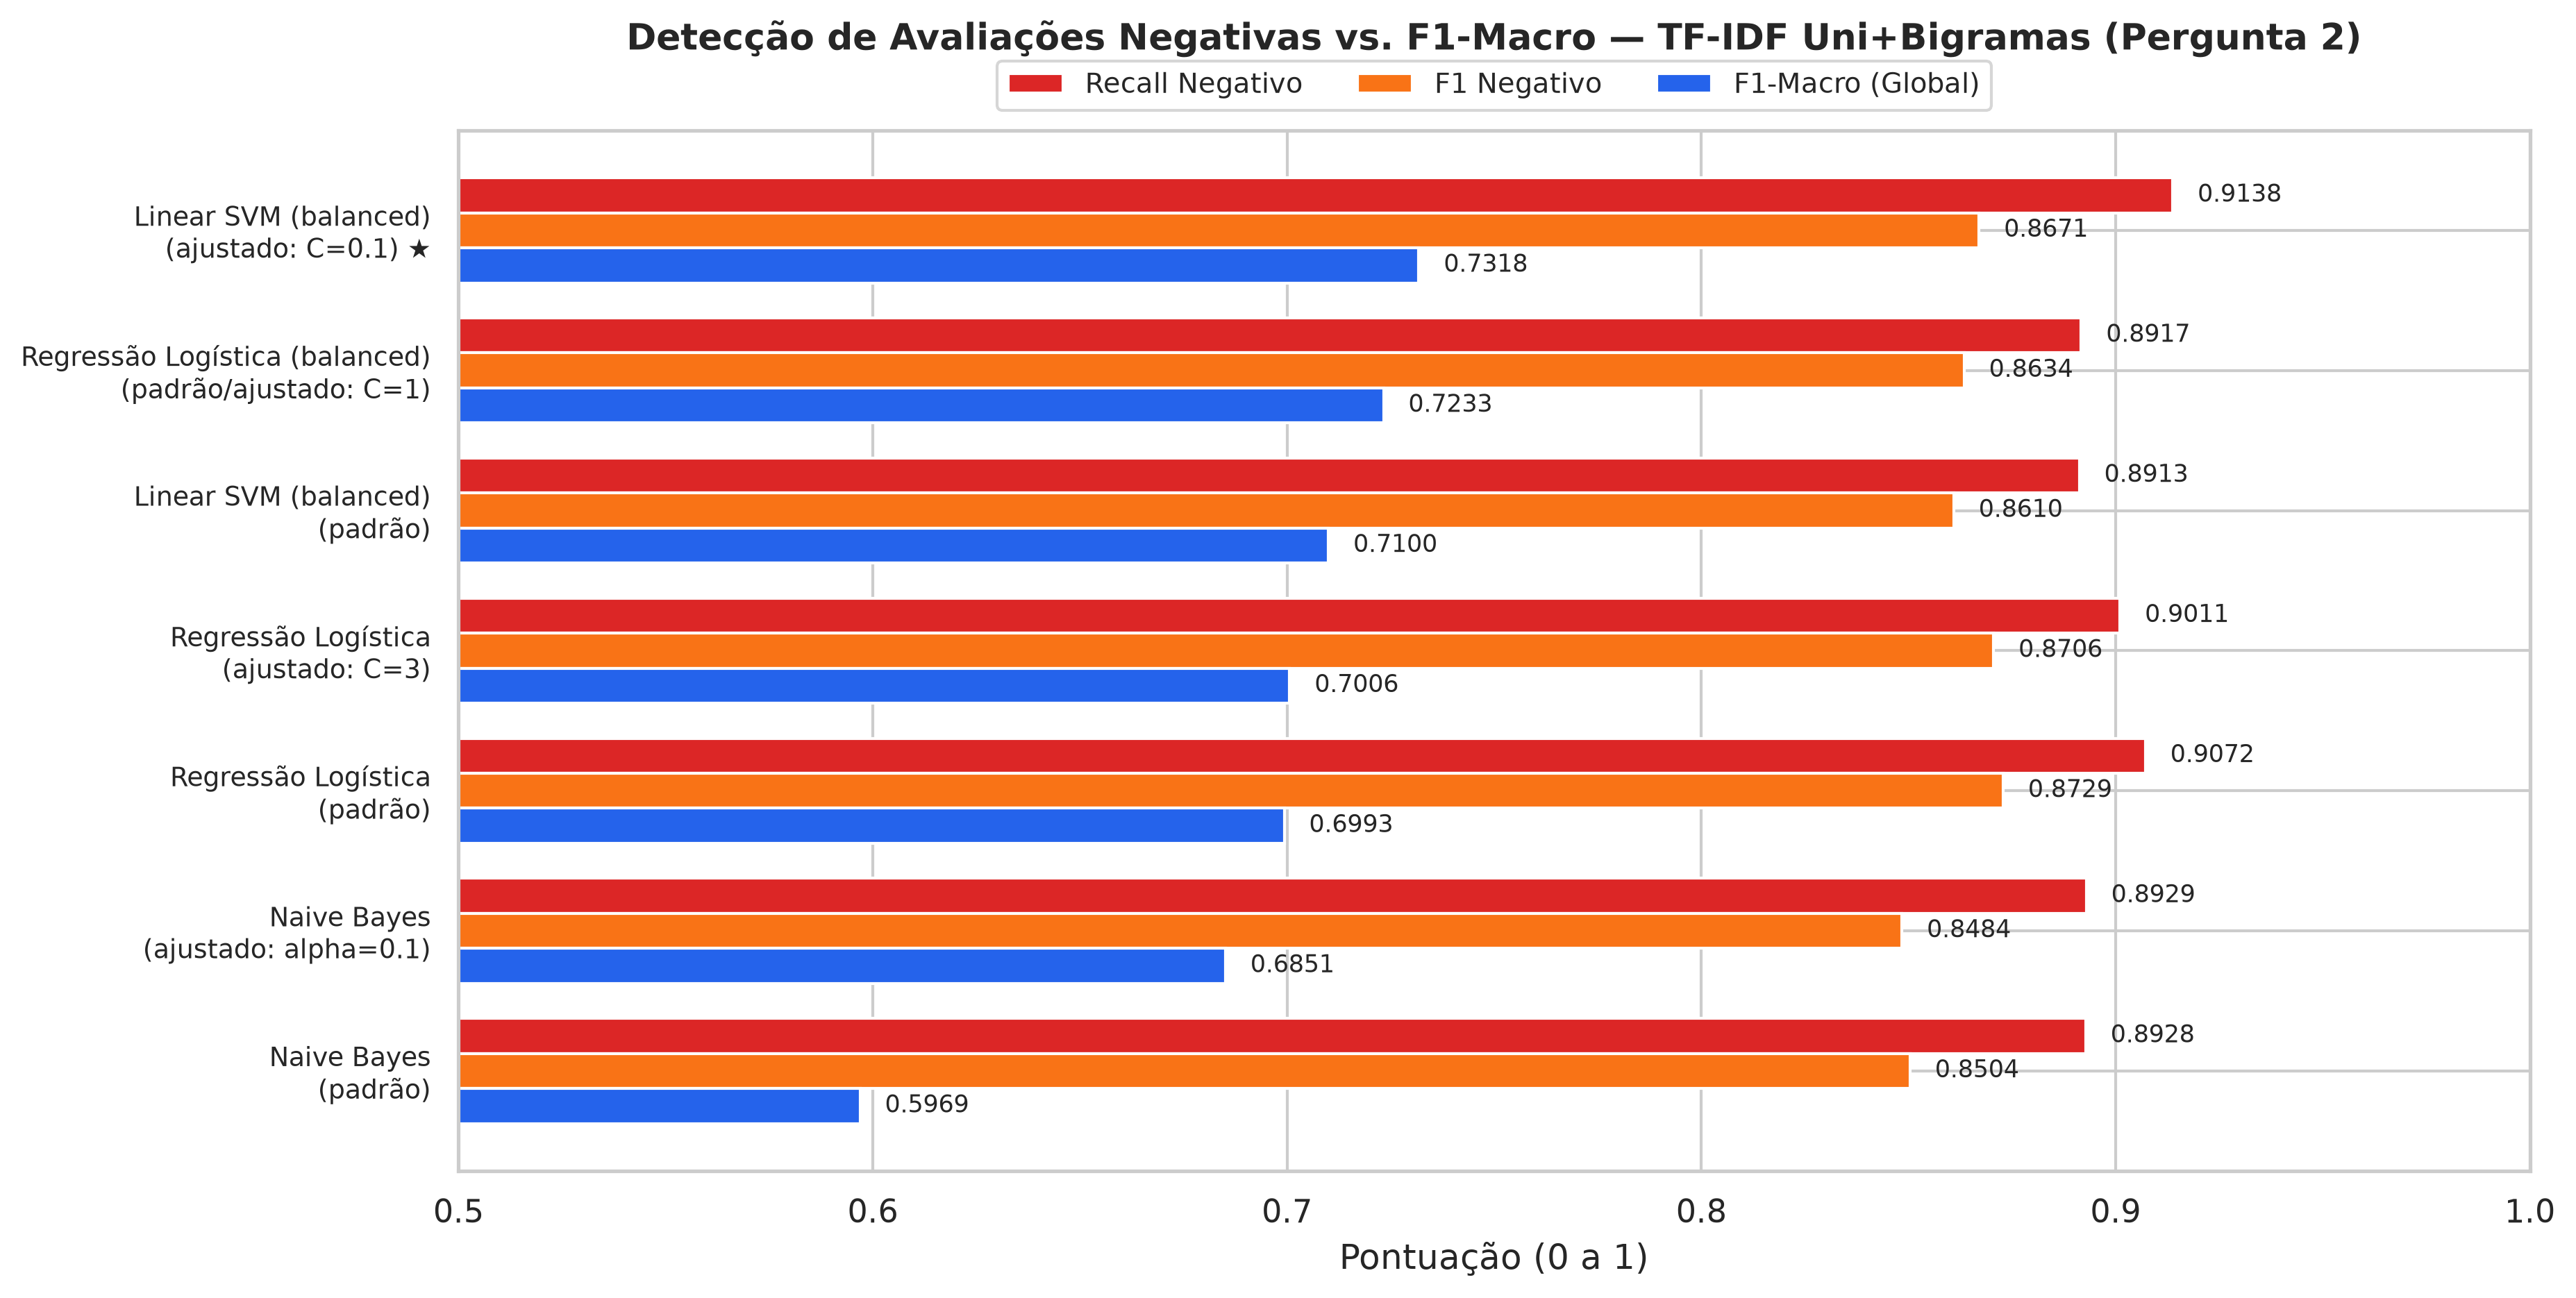

In [4]:
df_neg_view = df_comp[df_comp["representation"] == "tfidf_bi"][
    ["etapa", "classificador_label", "hiperparametros", "precision_Negativo", "recall_Negativo", "f1_Negativo", "recall_Neutro", "f1_macro", "accuracy"]
].sort_values("recall_Negativo", ascending=False)
display(df_neg_view.round(4))

cm_final = np.array(final_metrics["confusion_matrix"])
neg_total = cm_final[0].sum()
print(f"No modelo final (n_negativos={neg_total:,}):")
print(f"  Corretamente detectados como Negativo: {cm_final[0, 0]:,} ({100*cm_final[0, 0]/neg_total:.2f}% — Recall Negativo)")
print(f"  Suavizados para Neutro:                {cm_final[0, 1]:,} ({100*cm_final[0, 1]/neg_total:.2f}%)")
print(f"  Confundidos com Positivo (erro grave): {cm_final[0, 2]:,} ({100*cm_final[0, 2]/neg_total:.2f}%)")

fig15_path = plot_negative_recall_comparison(model_results)
display(Image(filename=str(fig15_path)))

---
## 3. Pergunta 3 — Quais erros aparecem com maior frequência?

Quantificamos todos os erros do modelo final no conjunto de teste (`n = 25.338`) por par `(Real → Previsto)` e inspecionamos exemplos reais extraídos de `X_test`, destacando a predominância de confusões com a **classe Neutra** e **avaliações mistas (produto bom + entrega/defeito ruim)**.

In [5]:
error_breakdown = analyze_error_breakdown(df_pred)
print(f"Total de erros no teste: {error_breakdown['n_errors']:,} / {error_breakdown['n_test']:,} ({error_breakdown['error_rate_pct']}%)")
print(f"Erros envolvendo a classe Neutra: {error_breakdown['errors_involving_neutral']:,} ({error_breakdown['errors_involving_neutral_pct']}% dos erros!)")
print(f"Erros extremos (Negativo <-> Positivo): {error_breakdown['extreme_polarity_errors']:,} ({error_breakdown['extreme_polarity_errors_pct']}% dos erros)")
print(f"Erros com indício de avaliação mista (elogio + ressalva/entrega): {error_breakdown['mixed_sentiment_errors_estimated']:,} ({error_breakdown['mixed_sentiment_errors_pct']}%)")
print(f"Extensão média: Acertos = {error_breakdown['mean_words_correct']} palavras | Erros = {error_breakdown['mean_words_error']} palavras")

display(pd.DataFrame(error_breakdown["pairs"]))

Total de erros no teste: 4,111 / 25,338 (16.22%)
Erros envolvendo a classe Neutra: 3,329 (80.98% dos erros!)
Erros extremos (Negativo <-> Positivo): 782 (19.02% dos erros)
Erros com indício de avaliação mista (elogio + ressalva/entrega): 1,086 (26.42%)
Extensão média: Acertos = 22.5 palavras | Erros = 25.12 palavras


,real,previsto,par,quantidade,pct_dos_erros,pct_do_teste,confianca_media
0,Neutro,Positivo,Neutro → Positivo,1242,30.21,4.90,0.5762
1,Positivo,Neutro,Positivo → Neutro,1042,25.35,4.11,0.4938
2,Neutro,Negativo,Neutro → Negativo,687,16.71,2.71,0.5236
3,Positivo,Negativo,Positivo → Negativo,578,14.06,2.28,0.4887
4,Negativo,Neutro,Negativo → Neutro,358,8.71,1.41,0.4628
5,Negativo,Positivo,Negativo → Positivo,204,4.96,0.81,0.4580


In [6]:
error_examples = extract_error_examples(df_pred, n_per_group=4)

rows_flat = []
for grp_key, items in error_examples.items():
    for item in items[:3]:  # 3 exemplos por categoria -> 18 erros reais bem categorizados
        rows_flat.append({
            "Tipo de Erro": item["categoria_erro"],
            "Nota": item["overall_rating"],
            "Real": item["sentiment_real"],
            "Previsto": item["sentiment_pred"],
            "Conf.": f"{item['confidence']:.1%}",
            "Recomenda": item["recommend_to_a_friend"],
            "Categoria": item["site_category_lv1"],
            "Texto Original": item["review_text_original"],
        })

df_err_examples = pd.DataFrame(rows_flat)
print(f"Exibindo {len(df_err_examples)} erros reais extraídos de X_test:")
display(df_err_examples)

Exibindo 18 erros reais extraídos de X_test:


,Tipo de Erro,Nota,Real,Previsto,Conf.,Recomenda,Categoria,Texto Original
0,Avaliação mista (produto vs. entrega/ressalva),4,Positivo,Neutro,75.0%,Yes,Suplementos e Vitaminas,"Produto é bom, porém a entrega não foi entregue no prazo prometido."
1,Avaliação mista (produto vs. entrega/ressalva),4,Positivo,Neutro,70.5%,Yes,Utilidades Domésticas,"Produto bom custo benefício, não é sofisticado. Mas entregue em perfeitas condições."
2,Avaliação mista (produto vs. entrega/ressalva),3,Neutro,Positivo,69.1%,Yes,Moda,"Produto de qualidade , Entrega muito boa ( 7 dias) , mas o tamanho das lentes é pequeno para o meu gosto."
3,Neutro confundido com Positivo,3,Neutro,Positivo,95.0%,Yes,Celulares e Smartphones,Amei recomendo e o melhor de tudo câmera perfeita_ e grande e fino maravilhoso
4,Neutro confundido com Positivo,3,Neutro,Positivo,93.8%,Yes,Celulares e Smartphones,Eu amei o meu produto é ótimo celular pode comprar
5,Neutro confundido com Positivo,3,Neutro,Positivo,92.9%,Yes,Casa e Construção,Produto muito bom e de ótima qualidade! Recomendo!!!
6,Neutro confundido com Negativo,3,Neutro,Negativo,93.2%,Yes,Wearable,"Horrível. Depois d um mês d espera, nao veio o produto q eu paguei, veio um outro relógio. E ainda nao devolveram meu dinheiro 1.500 rea..."
7,Neutro confundido com Negativo,3,Neutro,Negativo,92.5%,Yes,Bebês,"Infelizmente, sou mais uma insatisfeita com o péssimo atendimento com o cliente, não recebi o produto."
8,Neutro confundido com Negativo,3,Neutro,Negativo,90.8%,Yes,Celulares e Smartphones,Um dos aparelhos veio com defeito e não ligou enviei para troca pelo codigo de postagem e ate hoje não tive retorno.
9,Positivo confundido com Neutro,5,Positivo,Neutro,81.4%,Yes,TV e Home Theater,"Utilizei pouco a tv, mas me parece ser boa. Até o momento eu recomendaria."


---
## 4. Pergunta 4 — A regra de conversão de notas em sentimentos introduz ruído nos rótulos?

Investigamos dois sinais objetivos de ruído de rotulagem no `X_test`:
1. **Contradição entre nota e `recommend_to_a_friend`**: se os erros extremos do modelo (`Negativo → Positivo` e `Positivo → Negativo`) concentrarem uma proporção muito maior de recomendações contraditórias do que o conjunto de teste geral, fica provado que parte substancial desses "erros" decorre de rótulos ruidosos.
2. **Inspeção qualitativa** de casos com `nota == 1` previstos como `Positivo` com alta confiança e `nota == 5` previstos como `Negativo` com alta confiança (erros de clique, *"ainda não testei/abri"*, ironia).
3. **Experimento comparativo binário** (descartando a nota 3 em treino e teste, sem *data leakage*).

=== Evidência Quantitativa de Ruído nos Rótulos (X_test) ===
Negativo (nota 1-2) com recomenda='Yes' no teste geral:          543 / 6,520 (8.33%)
Negativo (nota 1-2) previsto Positivo c/ recomenda='Yes':        59 / 204 (28.92%)

Positivo (nota 4-5) com recomenda='No' no teste geral:           231 / 15,649 (1.48%)
Positivo (nota 4-5) previsto Negativo c/ recomenda='No':         49 / 578 (8.48%)

Casos Nota=1 previstos como Positivo: 99
Casos Nota=5 previstos como Negativo: 283
Avaliações nota 4-5 com 'ainda não / não testei / não abri': 180 (57 previstos como Negativo)


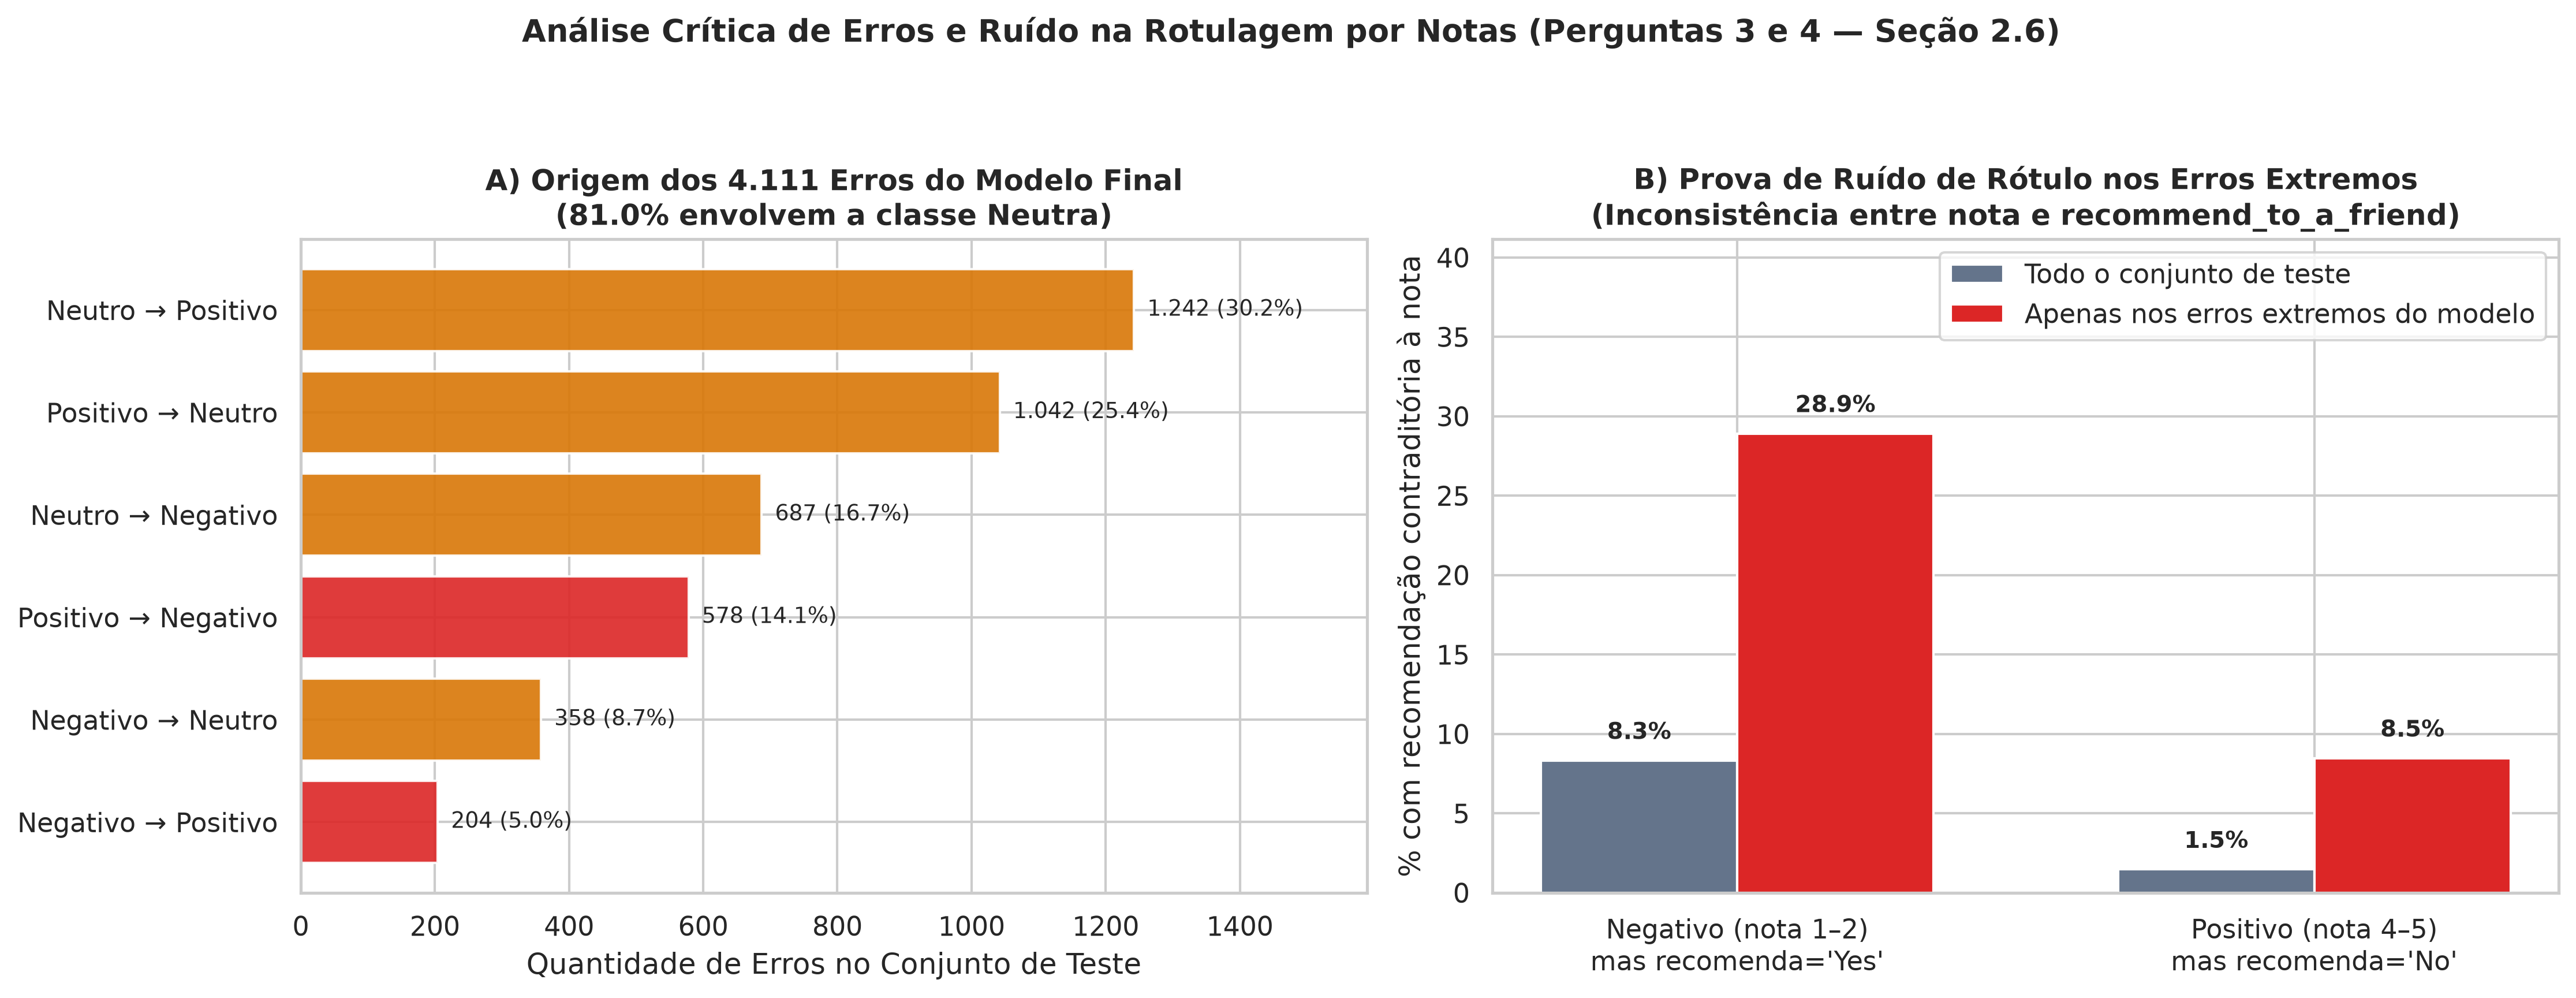

In [7]:
label_noise = analyze_label_noise(df_pred, top_n=6)

print("=== Evidência Quantitativa de Ruído nos Rótulos (X_test) ===")
print(f"Negativo (nota 1-2) com recomenda='Yes' no teste geral:          "
      f"{label_noise['neg_recommend_yes_all_test']:,} / {label_noise['n_test_negativo']:,} ({label_noise['neg_recommend_yes_all_test_pct']}%)")
print(f"Negativo (nota 1-2) previsto Positivo c/ recomenda='Yes':        "
      f"{label_noise['extreme_neg_pred_pos_recommend_yes']:,} / {label_noise['extreme_neg_pred_pos_total']:,} ({label_noise['extreme_neg_pred_pos_recommend_yes_pct']}%)")
print(f"\nPositivo (nota 4-5) com recomenda='No' no teste geral:           "
      f"{label_noise['pos_recommend_no_all_test']:,} / {label_noise['n_test_positivo']:,} ({label_noise['pos_recommend_no_all_test_pct']}%)")
print(f"Positivo (nota 4-5) previsto Negativo c/ recomenda='No':         "
      f"{label_noise['extreme_pos_pred_neg_recommend_no']:,} / {label_noise['extreme_pos_pred_neg_total']:,} ({label_noise['extreme_pos_pred_neg_recommend_no_pct']}%)")
print(f"\nCasos Nota=1 previstos como Positivo: {label_noise['nota1_pred_pos_total']:,}")
print(f"Casos Nota=5 previstos como Negativo: {label_noise['nota5_pred_neg_total']:,}")
print(f"Avaliações nota 4-5 com 'ainda não / não testei / não abri': {label_noise['pos_not_tested_or_received_count']:,} "
      f"({label_noise['pos_not_tested_pred_neg_count']:,} previstos como Negativo)")

fig14_path = plot_error_and_noise_analysis(error_breakdown, label_noise)
display(Image(filename=str(fig14_path)))

In [8]:
print("--- Exemplos reais: Nota 1 (Negativo) previstos como POSITIVO com alta confiança ---")
df_n1 = pd.DataFrame(label_noise["examples_nota1_pred_positivo"])[
    ["overall_rating", "sentiment_pred", "confidence", "recommend_to_a_friend", "site_category_lv1", "review_text_original"]
]
display(df_n1)

print("--- Exemplos reais: Nota 5 (Positivo) previstos como NEGATIVO com alta confiança ---")
df_n5 = pd.DataFrame(label_noise["examples_nota5_pred_negativo"])[
    ["overall_rating", "sentiment_pred", "confidence", "recommend_to_a_friend", "site_category_lv1", "review_text_original"]
]
display(df_n5)

--- Exemplos reais: Nota 1 (Negativo) previstos como POSITIVO com alta confiança ---


,overall_rating,sentiment_pred,confidence,recommend_to_a_friend,site_category_lv1,review_text_original
0,1,Positivo,0.8832,Yes,"Cama, Mesa e Banho",muito boa a entrega bem antes do previsto exelente loja superr recomendo
1,1,Positivo,0.8642,Yes,Móveis,Ótimo produto ...recomendo ..chegou antes do prazo
2,1,Positivo,0.8301,Yes,Informática,"Eu comprei e gostei muito, pelo preço e o que ele me oferece, valeu muito a pena"
3,1,Positivo,0.7924,Yes,Informática,produto excelente pra uso e ainda chegou antes do prazo muito obrigado recomendo.
4,1,Positivo,0.7883,Yes,Celulares e Smartphones,Excelente serviço de venda e entrega. Produto muito bonito.
5,1,Positivo,0.7529,Yes,Games,é muito bom mesmo. vale a pena.O texto de análise é muito curto.


--- Exemplos reais: Nota 5 (Positivo) previstos como NEGATIVO com alta confiança ---


,overall_rating,sentiment_pred,confidence,recommend_to_a_friend,site_category_lv1,review_text_original
0,5,Negativo,0.8844,Yes,Informática,"como posso avaliar o produto se consta entregue e não recebi o produto. E ninguém me da um posição, creio que vou ter entrar no PROCON ..."
1,5,Negativo,0.8685,Yes,Informática e Acessórios,"COMPREI NO DIA 05/20/2018, ATÉ O PRESENTE MOMENTO NÃO RECEBI O PRODUTO, E O PIOR, VC RECEBE UMA LIGAÇÃO DAS AMERICANAS PERGUNTANDO SE EU..."
2,5,Negativo,0.8642,Yes,Beleza e Perfumaria,"Não consigo avaliar o produto, pois ele não foi entregue! As lojas Americanas ofertou como alternativa somente o cancelamento da compra."
3,5,Negativo,0.8535,Yes,Informática,Não recebi ainda Não recebi ainda Não recebi ainda
4,5,Negativo,0.8267,Yes,Saúde,fica meio dificil de avaliar um produto que eu não recebi...
5,5,Negativo,0.8001,No,Suplementos e Vitaminas,Não recebi o produto que deveria ter sido entregue desde 06/03.


In [9]:
binary_comp = evaluate_binary_scenario(X_train, y_train, X_test, y_test)
print("=== Experimento Complementar: Cenário Binário (sem Nota 3, sem data leakage) ===")
print(f"Treino binário: {binary_comp['n_train_binary']:,} (descartados {binary_comp['discarded_neutral_train']:,} Neutros)")
print(f"Teste binário:  {binary_comp['n_test_binary']:,} (descartados {binary_comp['discarded_neutral_test']:,} Neutros)")
print(f"3 Classes (Padrão) -> Acurácia: {final_metrics['accuracy']:.4f} | F1-Macro: {final_metrics['f1_macro']:.4f}")
print(f"2 Classes (Binário)-> Acurácia: {binary_comp['accuracy']:.4f} | F1-Macro: {binary_comp['f1_macro']:.4f} "
      f"| F1-Neg: {binary_comp['f1_Negativo']:.4f} | F1-Pos: {binary_comp['f1_Positivo']:.4f}")

=== Experimento Complementar: Cenário Binário (sem Nota 3, sem data leakage) ===
Treino binário: 88,678 (descartados 12,674 Neutros)
Teste binário:  22,169 (descartados 3,169 Neutros)
3 Classes (Padrão) -> Acurácia: 0.8378 | F1-Macro: 0.7318
2 Classes (Binário)-> Acurácia: 0.9477 | F1-Macro: 0.9388 | F1-Neg: 0.9155 | F1-Pos: 0.9621


---
## 5. Pergunta 5 — O desempenho se mantém em avaliações de produtos ou categorias diferentes?

Agrupamos o conjunto de teste por `site_category_lv1` nas **Top 10 categorias** em volume (incluindo as Top 5 e **`Móveis`**, que já havia se destacado na EDA por apresentar 43,9% de avaliações negativas).

,categoria,n_test,pct_negativo,pct_neutro,pct_positivo,accuracy,f1_macro,f1_Negativo,f1_Neutro,f1_Positivo,recall_Negativo,recall_Neutro,recall_Positivo
0,Celulares e Smartphones,4055,19.2,11.5,69.3,0.8358,0.6920,0.8314,0.3350,0.9097,0.9038,0.2925,0.9068
1,Eletroportáteis,2317,16.9,11.4,71.6,0.8502,0.7232,0.8407,0.4134,0.9157,0.8954,0.3736,0.9157
2,Beleza e Perfumaria,1784,25.4,12.0,62.6,0.8380,0.7322,0.8574,0.4388,0.9004,0.9161,0.4019,0.8899
3,Utilidades Domésticas,1546,25.1,13.3,61.6,0.8461,0.7640,0.8774,0.5099,0.9046,0.8943,0.5000,0.9013
4,Informática e Acessórios,1447,31.8,13.0,55.2,0.8189,0.7147,0.8859,0.3871,0.8711,0.9196,0.3511,0.8711
5,TV e Home Theater,1444,22.3,10.7,67.0,0.8255,0.6920,0.8309,0.3455,0.8995,0.8851,0.3355,0.8842
6,Móveis,1303,42.7,15.8,41.5,0.8289,0.7593,0.8983,0.5051,0.8744,0.9299,0.4854,0.8558
7,Brinquedos,941,27.3,12.1,60.6,0.8555,0.7633,0.8787,0.4977,0.9135,0.9300,0.4737,0.8982
8,Casa e Construção,852,33.2,14.2,52.6,0.8439,0.7523,0.8938,0.4660,0.8972,0.9364,0.3967,0.9062
9,Informática,822,28.6,15.8,55.6,0.8224,0.7453,0.8687,0.4848,0.8824,0.9149,0.4308,0.8862


Melhor F1-Macro: Utilidades Domésticas (0.7640, n=1,546)
Menor F1-Macro:  Celulares e Smartphones (0.6920, n=4,055)
Amplitude entre Top 10 categorias: 0.0720 pontos de F1-Macro


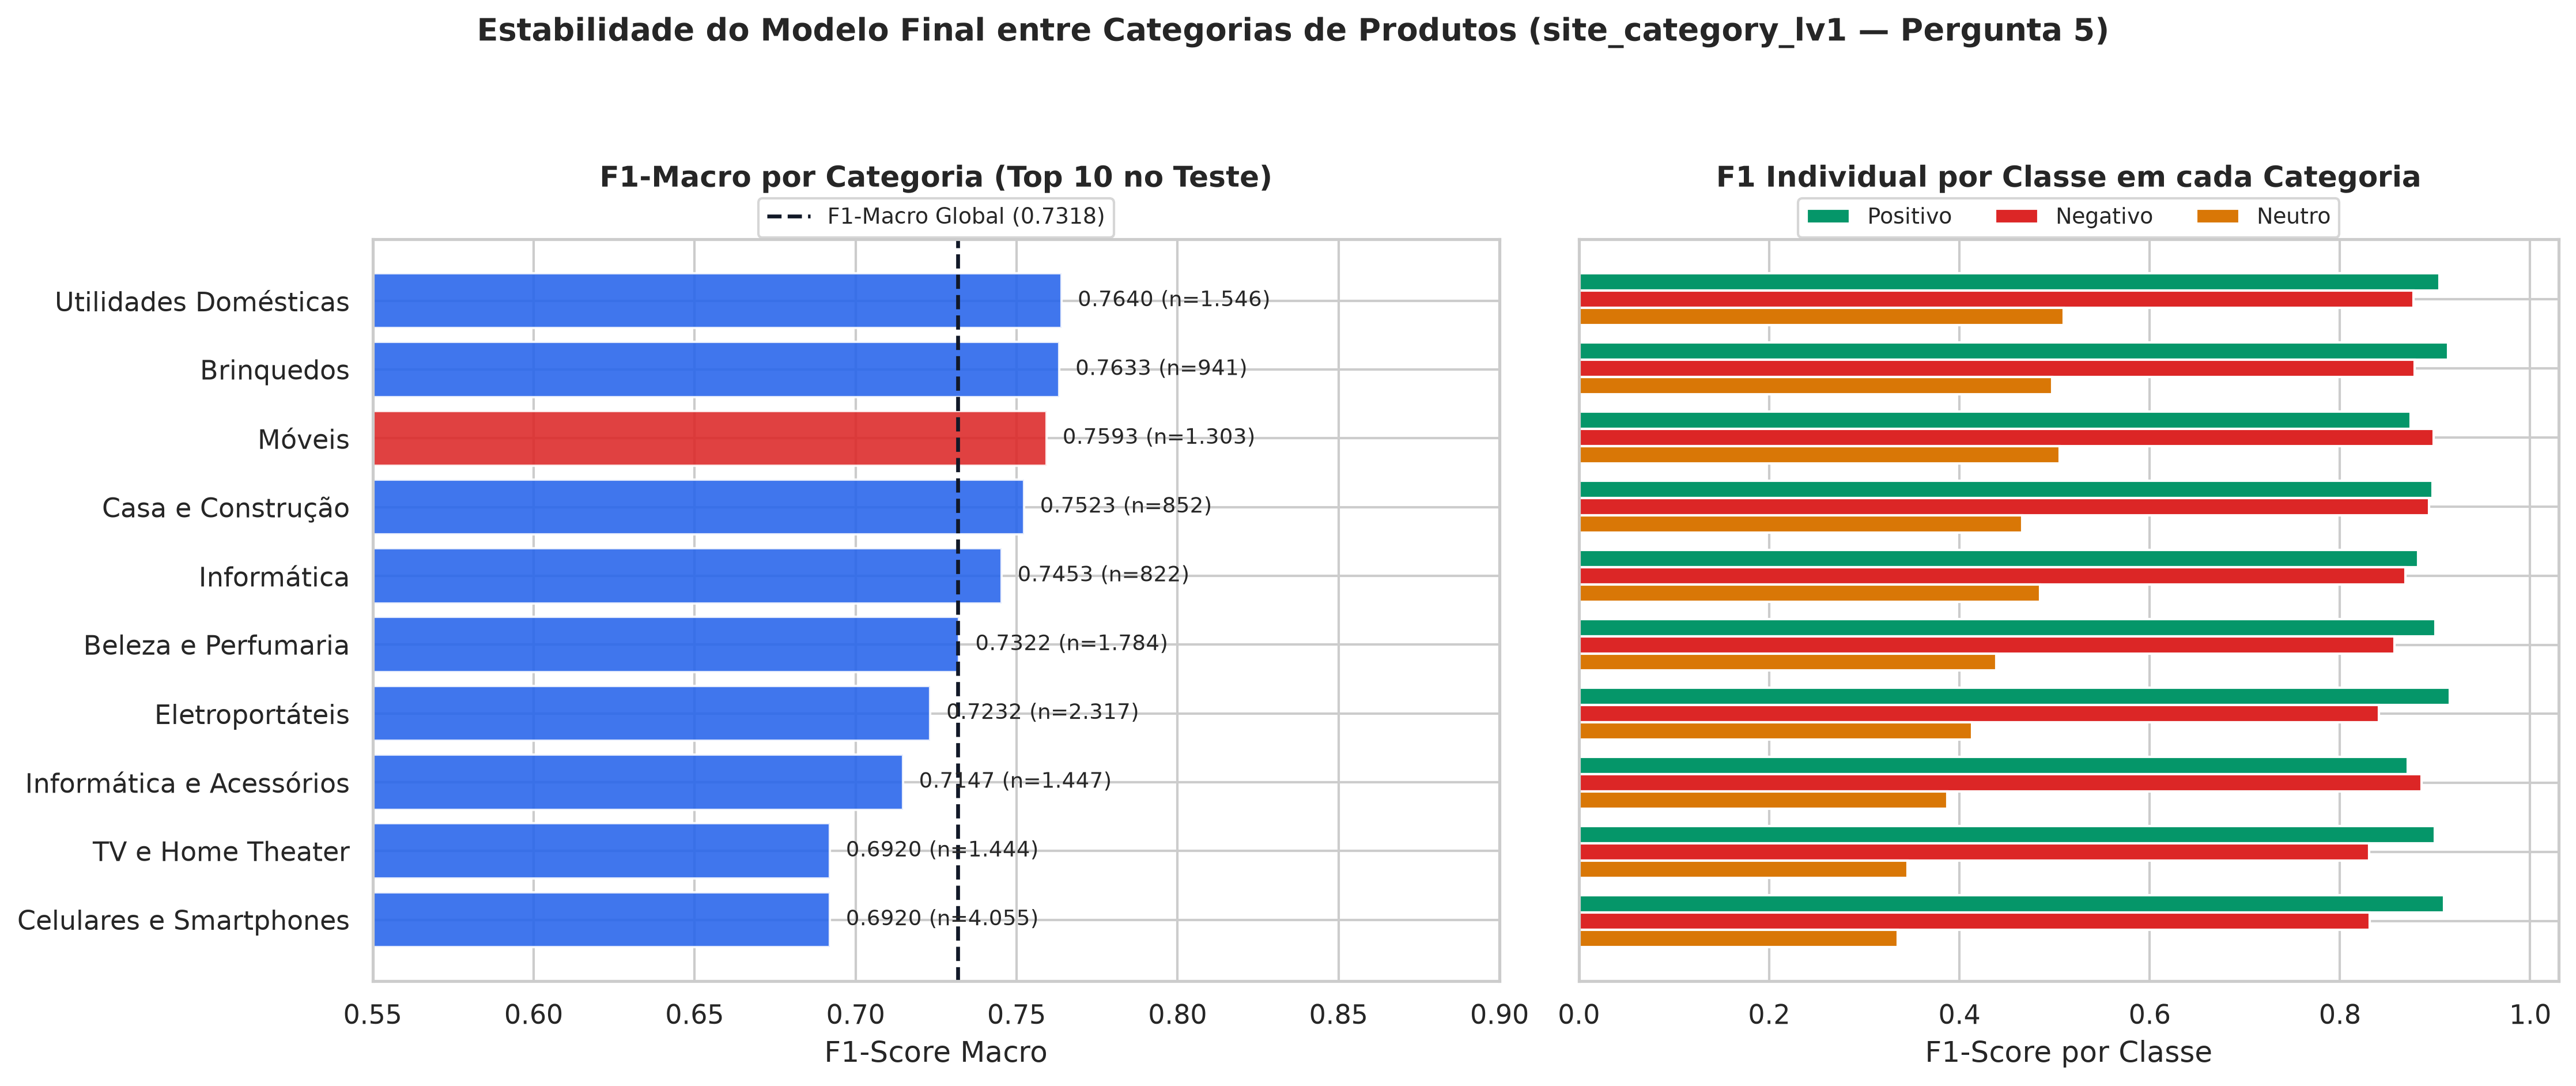

In [10]:
df_cat = evaluate_by_category(df_pred, top_n=10)
display(df_cat)

best_cat = df_cat.loc[df_cat["f1_macro"].idxmax()]
worst_cat = df_cat.loc[df_cat["f1_macro"].idxmin()]
spread = best_cat["f1_macro"] - worst_cat["f1_macro"]
print(f"Melhor F1-Macro: {best_cat['categoria']} ({best_cat['f1_macro']:.4f}, n={best_cat['n_test']:,})")
print(f"Menor F1-Macro:  {worst_cat['categoria']} ({worst_cat['f1_macro']:.4f}, n={worst_cat['n_test']:,})")
print(f"Amplitude entre Top 10 categorias: {spread:.4f} pontos de F1-Macro")

fig13_path = plot_category_performance(df_cat, overall_f1_macro=final_metrics["f1_macro"])
display(Image(filename=str(fig13_path)))

---
## 6. Validação em Exemplos Inéditos, Explicabilidade por Token e Exportação Final

Testamos o pipeline final em **6 avaliações inéditas** (nunca vistas no treino) cobrindo elogio claro, negação explícita, avaliação mista, neutro moderado, negação com polaridade positiva e ironia/sarcasmo, inspecionando os tokens que mais influenciaram cada decisão. Por fim, exportamos `reports/evaluation_summary.json` para o Streamlit (`app.py`).

In [11]:
unseen_samples = [
    "Produto excelente, superou minhas expectativas e chegou antes do prazo!",
    "O produto não funciona direito e não recomendo para ninguém.",
    "O celular é ótimo, mas a entrega atrasou duas semanas e veio com a caixa rasgada.",
    "Produto mediano, funciona bem para o básico, nada demais pelo preço.",
    "Não trava, bateria dura bastante e não me arrependo da compra!",
    "Parabéns pela transportadora incrível, só levou dois meses para entregar um produto quebrado.",
]
unseen_predictions = [predict_single_review(txt, best_pipe, top_k=6) for txt in unseen_samples]

summary = {
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "final_model_info": {
        "representation": model_results["final"]["representation"],
        "representation_label": REP_LABELS[model_results["final"]["representation"]],
        "classifier": model_results["final"]["classifier"],
        "classifier_label": CLF_LABELS[model_results["final"]["classifier"]],
        "best_params": model_results["final"]["best_params"],
        "cv_f1_macro": round(float(model_results["final"]["cv_f1_macro"]), 4),
        "test_f1_macro": round(final_metrics["f1_macro"], 4),
        "test_accuracy": round(final_metrics["accuracy"], 4),
        "test_f1_weighted": round(final_metrics["f1_weighted"], 4),
        "per_class": final_metrics["per_class"],
        "confusion_matrix": final_metrics["confusion_matrix"],
        "confusion_matrix_normalized": final_metrics["confusion_matrix_normalized"],
    },
    "best_accuracy_model": {
        "representation": "tfidf_bi",
        "classifier": "logreg",
        "accuracy": round(float(best_acc_row["accuracy"]), 4),
        "f1_macro": round(float(best_acc_row["f1_macro"]), 4),
        "recall_Neutro": round(float(best_acc_row["recall_Neutro"]), 4),
    },
    "error_breakdown": error_breakdown,
    "error_examples": error_examples,
    "label_noise_analysis": label_noise,
    "category_performance": df_cat.to_dict(orient="records"),
    "binary_scenario_comparison": binary_comp,
    "unseen_examples_validation": unseen_predictions,
    "figures": {
        "confusion_matrices_comparison": str(fig12_path.relative_to(PROJECT_ROOT)).replace("\\", "/"),
        "category_performance": str(fig13_path.relative_to(PROJECT_ROOT)).replace("\\", "/"),
        "error_and_noise_analysis": str(fig14_path.relative_to(PROJECT_ROOT)).replace("\\", "/"),
        "negative_recall_comparison": str(fig15_path.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    },
}
EVALUATION_SUMMARY_PATH.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

unseen_rows = []
for item in unseen_predictions:
    top3 = ", ".join(f"{t['token']} ({t['contrib_classe_prevista']:+.2f})" for t in item["top_tokens_predicted"][:3])
    unseen_rows.append({
        "Avaliação Inédita": item["texto_original"],
        "Texto Tratado": item["texto_tratado"],
        "Previsto": item["sentimento"],
        "Confiança": f"{item['probabilidades'][item['sentimento']]:.1%}",
        "Top 3 Tokens/Bigramas": top3,
    })
display(pd.DataFrame(unseen_rows))

print(f"\n[OK] Resumo exportado em: {EVALUATION_SUMMARY_PATH}")
print("[OK] Figuras salvas:", summary["figures"])

,Avaliação Inédita,Texto Tratado,Previsto,Confiança,Top 3 Tokens/Bigramas
0,"Produto excelente, superou minhas expectativas e chegou antes do prazo!",produto excelente superou expectativas chegou antes prazo,Positivo,91.4%,"excelente (+0.72), superou (+0.20), expectativas (+0.20)"
1,O produto não funciona direito e não recomendo para ninguém.,produto não funciona direito não recomendo ninguém,Negativo,96.2%,"não recomendo (+0.82), não (+0.70), não funciona (+0.53)"
2,"O celular é ótimo, mas a entrega atrasou duas semanas e veio com a caixa rasgada.",celular ótimo mas entrega atrasou duas semanas veio caixa rasgada,Positivo,52.5%,"ótimo (+0.38), veio (-0.19), celular ótimo (+0.10)"
3,"Produto mediano, funciona bem para o básico, nada demais pelo preço.",produto mediano funciona bem básico nada demais preço,Neutro,58.1%,"básico (+0.28), nada demais (+0.15), bem básico (+0.14)"
4,"Não trava, bateria dura bastante e não me arrependo da compra!",não trava bateria dura bastante não arrependo compra,Positivo,69.2%,"não (-0.51), não trava (+0.39), não arrependo (+0.25)"
5,"Parabéns pela transportadora incrível, só levou dois meses para entregar um produto quebrado.",parabéns transportadora incrível só levou dois meses entregar produto quebrado,Positivo,46.9%,"incrível (+0.25), parabéns (+0.19), quebrado (-0.15)"



[OK] Resumo exportado em: C:\Users\Dell\Downloads\PROJETO_DE_IA\projeto-ia-sentimentos-b2w-main\reports\evaluation_summary.json
[OK] Figuras salvas: {'confusion_matrices_comparison': 'reports/figures/12_matrizes_confusao_comparacao.png', 'category_performance': 'reports/figures/13_desempenho_por_categoria.png', 'error_and_noise_analysis': 'reports/figures/14_analise_erros_e_ruido.png', 'negative_recall_comparison': 'reports/figures/15_recall_negativo_comparacao.png'}
